# EMQA_L3_acf_clust

**Autocorrelation function (lags 1-30) of the daily shocks of the Romanian base price and of their squares, 2019-01-01 to 2026-10-31**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_acf_clust/EMQA_L3_acf_clust.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## The sign is unpredictable, the size is not

Ljung–Box statistic $Q(10)=T(T+2)\sum_{k\le10}\hat\rho_k^2/(T-k)$ on the shocks $\varepsilon_t$ and on $\varepsilon_t^2$; Engle's ARCH-LM test with 10 lags.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


### Numbers on the slide

In [6]:
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
lb_e, lb_e2 = acorr_ljungbox(E_PCT, [10]), acorr_ljungbox(E_PCT ** 2, [10])
lm = het_arch(E_PCT, nlags=10)
slide('Ljung-Box Q(10), shocks', 'facts.lb_e', lb_e['lb_stat'].iloc[0], 1)
slide('  p-value', 'facts.lb_e_p', lb_e['lb_pvalue'].iloc[0], 3)
slide('Ljung-Box Q(10), squared shocks', 'facts.lb_e2', lb_e2['lb_stat'].iloc[0], 1)
slide('ARCH-LM, 10 lags', 'facts.lm', lm[0], 1)
print('ARCH-LM p-value:', lm[1])

Ljung-Box Q(10), shocks                                    13.8   [facts.lb_e]
  p-value                                                  0.18   [facts.lb_e_p]
Ljung-Box Q(10), squared shocks                            120.0   [facts.lb_e2]
ARCH-LM, 10 lags                                           93.7   [facts.lm]
ARCH-LM p-value: 9.635333752275403e-16


### Chart

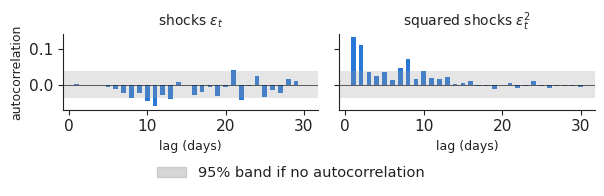

In [7]:
from matplotlib.patches import Patch
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.0), sharey=True)
K = 30
ci = 1.96 / np.sqrt(len(E_PCT))
for ax, s_, ttl in [(axs[0], E_PCT, r'shocks $\varepsilon_t$'), (axs[1], E_PCT ** 2, r'squared shocks $\varepsilon_t^2$')]:
    ax.bar(range(1, K + 1), acf(s_, nlags=K)[1:], color=C_PCT, width=0.6)
    ax.axhspan(-ci, ci, color='#9a9a9a', alpha=0.25, lw=0)
    ax.axhline(0, color='#222222', lw=0.5)
    ax.set_title(ttl, fontsize=10)
    ax.set_xlabel('lag (days)', fontsize=9)
axs[0].set_ylabel('autocorrelation', fontsize=9)
legend_bottom(fig, handles=[Patch(color='#9a9a9a', alpha=0.4)], labels=['95% band if no autocorrelation'], ncol=1)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('acf_clust.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()